# Import lib

In [1]:
from offaxsim.layers import build_hwp_stack, build_klopfenstein_arc, wrap_with_symmetric_arc
from offaxsim.simulation import SingleLayerSimulation
from offaxsim.simulation import MultiLayerSimulation
import numpy as np
import matplotlib.pyplot as plt


# Single HWP
## Calculate Jones and Mueller matrix

In [2]:
theta_deg = 10
freq = np.arange(60., 150., 30.)*1e9
rho_arr = np.arange(0, 360.01, 1.0)

no = 3.059 - 1j*0.000137655
ne = 3.397 - 1j*0.00023779

thickness_HWP = 5e-3
psi_deg = 30


sim = SingleLayerSimulation(theta_deg)
J, M = sim.run(
    freq,rho_arr,
    no,ne,
    thickness_HWP,
    psi_deg,
)

100%|██████████| 361/361 [00:00<00:00, 2483.01it/s]


## Compare with the original result

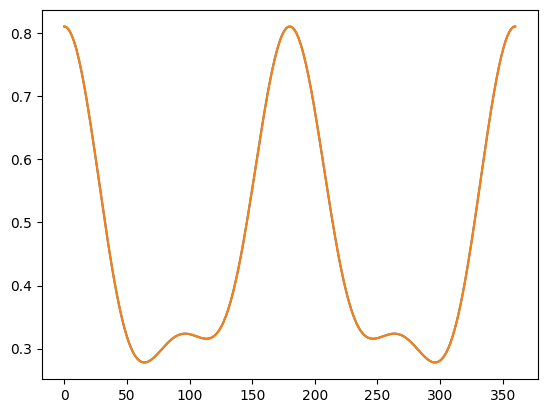

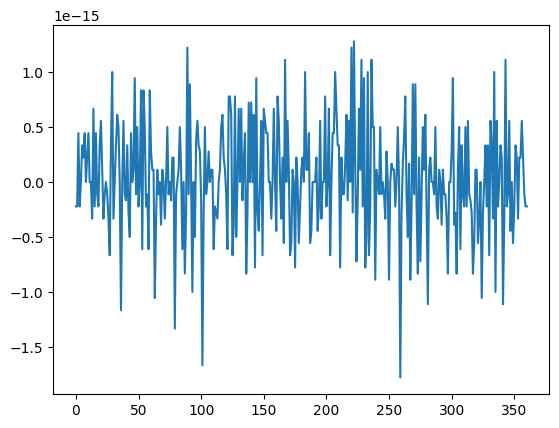

In [3]:
tpp_arr = J[:, :, 0, 0]
tss_arr = J[:, :, 1, 1]

TM = np.abs(tpp_arr)**2
TE = np.abs(tss_arr)**2

f = np.load("original/hoshino_single_code.npz")
TE_hoshino = f["TE"]

plt.plot(TE[:,0])
plt.plot(TE_hoshino[:,0])
plt.show()


plt.plot(TE_hoshino[:,0] - TE[:,0])
plt.show()

# Multi-layer HWP including isotropic ARC on both sides
## Calculate Jones and Mueller matrix

In [4]:
theta_deg = 10
freq = np.arange(60., 150., 30.)*1e9
rho_arr = np.arange(0, 360.01, 1.0)

no = 3.059 - 1j*0.000137655
ne = 3.397 - 1j*0.00023779

# HWP
thickness_HWP = np.ones(5)*5e-3
opt_axis_HWP = np.array([88.65, 61.68, 0, 61.68, 88.65])
psi_deg = 10
layer_HWP = build_hwp_stack(no, ne, thickness_HWP, psi_deg, opt_axis_HWP)

# ARC (option)
h = 2e-3
num = 11
ns = 3.397
n0 = 1.0
Gamma_m = 0.03878242227997966
layer_ARC = build_klopfenstein_arc(h, num, ns, n0, Gamma_m)

stack = wrap_with_symmetric_arc(layer_HWP, layer_ARC)  # with ARC
# stack = layer_HWP                                    # without ARC

sim = MultiLayerSimulation(theta_deg)
J, M = sim.run(freq, rho_arr, stack)


100%|██████████| 361/361 [00:02<00:00, 150.23it/s]


## Compare with the original result

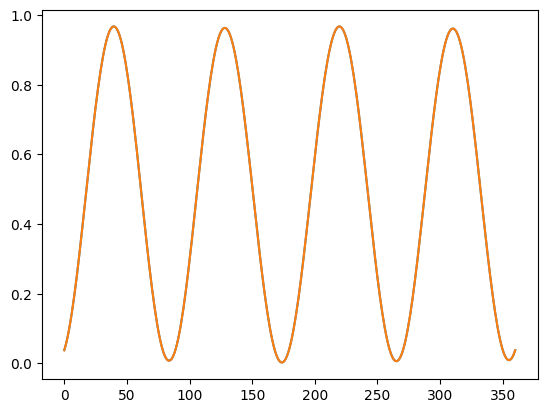

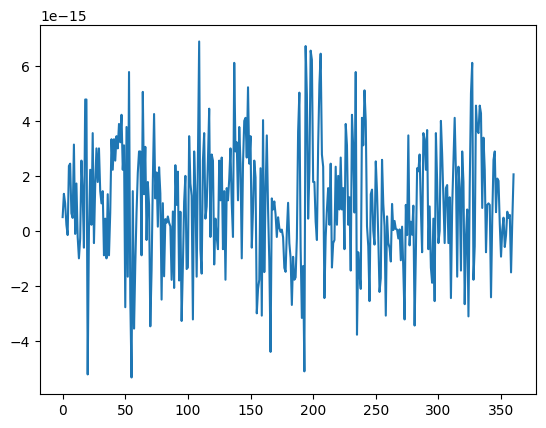

In [5]:
tpp_arr = J[:, :, 0, 0]
tss_arr = J[:, :, 1, 1]

TM = np.abs(tpp_arr)**2
TE = np.abs(tss_arr)**2

f = np.load('original/hoshino.npz')
TE_hoshino = f["IoutTE"]
TM_hoshino = f["IoutTM"]

freqi = 0
plt.plot(TE_hoshino[freqi])
plt.plot(TE[:,freqi])
plt.show()

plt.plot(TE_hoshino[freqi]-TE[:,freqi])
plt.show()

# Uninstall

In [6]:
!pip uninstall -y offaxsim

Found existing installation: offaxsim 0.1.0
Uninstalling offaxsim-0.1.0:
  Successfully uninstalled offaxsim-0.1.0
